# sklearn digits + Logistic Regression

2026-10-04

依次完成：load_digits() → 看 data/images/target 的 shape → 看几张数字图片 → train_test_split → 建 LogisticRegression → fit → predict → accuracy → confusion matrix → 找几张预测错误的图片看看。

这里的重点不是背 sklearn API，而是第一次完整经历  
$$
\text{数据}\rightarrow\text{划分}\rightarrow\text{训练}\rightarrow\text{预测}\rightarrow\text{评估}\rightarrow\text{分析错误}
$$

这套流程。完成线：能回答“数据长什么样、模型输入多少维、十分类怎么输出、准确率多少、哪些数字容易混淆”即可。

## sklearn digits 数据结构

In [1]:
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import numpy as np

In [2]:
digits = load_digits()
digits.keys()

dict_keys(['data', 'target', 'frame', 'feature_names', 'target_names', 'images', 'DESCR'])

In [3]:
X = digits.data  # 图片展开为了64维的向量，逻辑回归使用向量（若是CNN则使用image矩阵）
y = digits.target  # 结果对应的数字
Y = np.eye(10)[y]  # 结果转化为onehot向量
X, y, Y

(array([[ 0.,  0.,  5., ...,  0.,  0.,  0.],
        [ 0.,  0.,  0., ..., 10.,  0.,  0.],
        [ 0.,  0.,  0., ..., 16.,  9.,  0.],
        ...,
        [ 0.,  0.,  1., ...,  6.,  0.,  0.],
        [ 0.,  0.,  2., ..., 12.,  0.,  0.],
        [ 0.,  0., 10., ..., 12.,  1.,  0.]], shape=(1797, 64)),
 array([0, 1, 2, ..., 8, 9, 8], shape=(1797,)),
 array([[1., 0., 0., ..., 0., 0., 0.],
        [0., 1., 0., ..., 0., 0., 0.],
        [0., 0., 1., ..., 0., 0., 0.],
        ...,
        [0., 0., 0., ..., 0., 1., 0.],
        [0., 0., 0., ..., 0., 0., 1.],
        [0., 0., 0., ..., 0., 1., 0.]], shape=(1797, 10)))

In [4]:
digits.images[0], digits.images[0].shape, digits.data[0], digits.data[0].shape # image为8x8，与data一一对应

(array([[ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.],
        [ 0.,  0., 13., 15., 10., 15.,  5.,  0.],
        [ 0.,  3., 15.,  2.,  0., 11.,  8.,  0.],
        [ 0.,  4., 12.,  0.,  0.,  8.,  8.,  0.],
        [ 0.,  5.,  8.,  0.,  0.,  9.,  8.,  0.],
        [ 0.,  4., 11.,  0.,  1., 12.,  7.,  0.],
        [ 0.,  2., 14.,  5., 10., 12.,  0.,  0.],
        [ 0.,  0.,  6., 13., 10.,  0.,  0.,  0.]]),
 (8, 8),
 array([ 0.,  0.,  5., 13.,  9.,  1.,  0.,  0.,  0.,  0., 13., 15., 10.,
        15.,  5.,  0.,  0.,  3., 15.,  2.,  0., 11.,  8.,  0.,  0.,  4.,
        12.,  0.,  0.,  8.,  8.,  0.,  0.,  5.,  8.,  0.,  0.,  9.,  8.,
         0.,  0.,  4., 11.,  0.,  1., 12.,  7.,  0.,  0.,  2., 14.,  5.,
        10., 12.,  0.,  0.,  0.,  0.,  6., 13., 10.,  0.,  0.,  0.]),
 (64,))

In [5]:
# 数据集划分
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
Y_train = np.eye(10)[y_train]

## 逻辑回归

$$
线性函数z=w^Tx+b\to p= softmax(z) \to 交叉熵loss \to w,b更新
$$

In [6]:
def softmax0(z):
    z = np.exp(z)
    sum = np.sum(z, axis=1, keepdims=True)
    z /= sum
    return z

# 推荐版本
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)

### `np.sum()`函数详解

它的常见形式是：
```
np.sum(
    a,
    axis=None,
    dtype=None,
    out=None,
    keepdims=False,
    initial=0,
    where=True
)
```

最重要的参数可以这样理解。
- a：要进行求和的数组。
- ***axis：*** 沿哪个轴压缩求和。0对列求和，1对行求和
- dtype：指定求和结果的数据类型。
- out：把结果写入提前准备好的数组，一般很少自己用。
- keepdims：求和之后，要不要保留被压缩的那个维度。
- initial：给求和指定一个初始值。
- where：只对满足条件的位置求和。

In [7]:
def train(alpha, epochs):
    loss_history = []
    
    w = np.zeros((X_train.shape[1], 10))
    b = np.zeros(10)
    
    for eopch in range(epochs):
        z = X_train @ w + b # numsx10
        p = softmax(z) # numsx10，每一行是10维的概率向量
        
        # loss
        eps = 1e-12
        loss = -np.mean(np.sum(Y_train * np.log(p + eps), axis=1))
        loss_history.append(loss)
        
        dw = X_train.T @ (p - Y_train) / X_train.shape[0]
        db = np.mean(p - Y_train, axis=0)
    
        w -= alpha * dw
        b -= alpha * db

    return w, b, loss_history

In [8]:
w, b, lh = train(0.01, 500)

In [9]:
type(b), type(lh), len(lh), lh[::100], lh[-1]

(numpy.ndarray,
 list,
 500,
 [np.float64(2.3025850929840455),
  np.float64(0.16870065277653287),
  np.float64(0.12103660229613276),
  np.float64(0.09911011119904102),
  np.float64(0.08543015512831441)],
 np.float64(0.07581507471155573))

In [10]:
# 训练集
P_train = softmax(X_train @ w + b)
pred_train = np.argmax(P_train, axis=1)
train_acc = np.mean(pred_train == y_train)

In [11]:
# 测试集

P_test = softmax(X_test @ w + b)
pred_test = np.argmax(P_test, axis=1)
test_acc = np.mean(pred_test == y_test)

In [12]:
train_acc, test_acc

(np.float64(0.9874739039665971), np.float64(0.9694444444444444))

## 结果分析

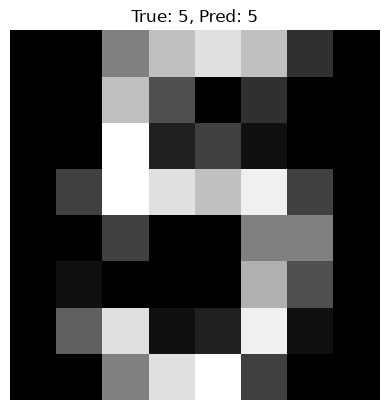

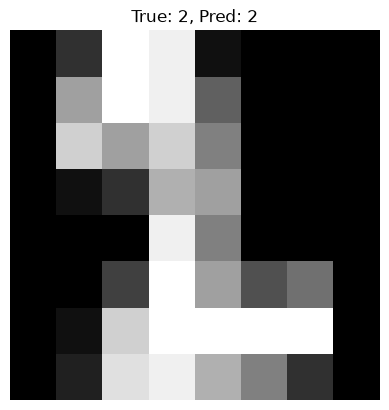

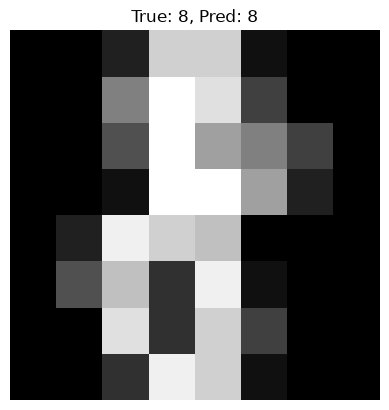

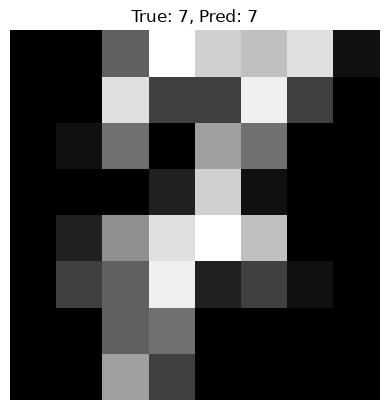

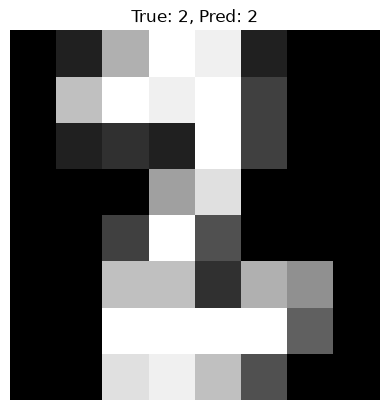

In [13]:
# 正确样本
right_idx = np.where(pred_test == y_test)[0][:5]
import matplotlib.pyplot as plt

for idx in right_idx:
    plt.figure()
    plt.imshow(X_test[idx].reshape(8, 8), cmap="gray")
    plt.title(f"True: {y_test[idx]}, Pred: {pred_test[idx]}")
    plt.axis("off")
    plt.show()

[  3  36  51  89  93 124 127 140 156 228 233]
错分数量： 11


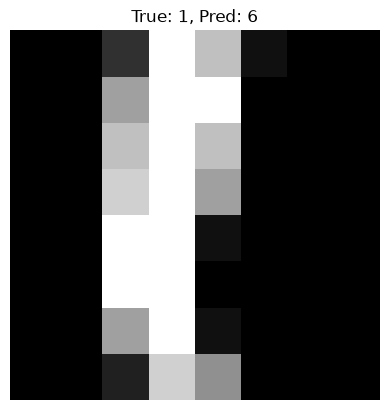

1概率=0.27，6概率=0.39


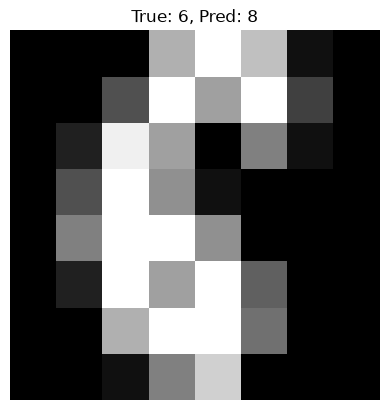

6概率=0.07，8概率=0.78


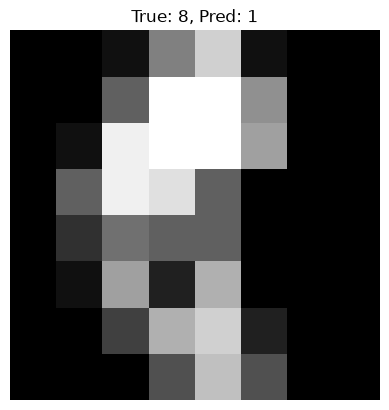

8概率=0.01，1概率=0.97


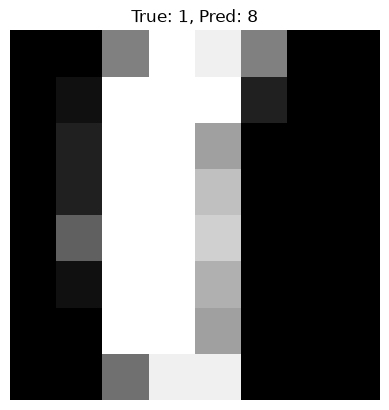

1概率=0.17，8概率=0.55


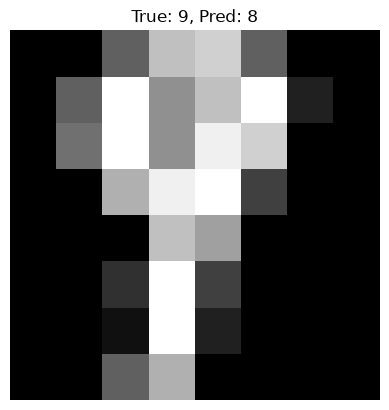

9概率=0.38，8概率=0.40


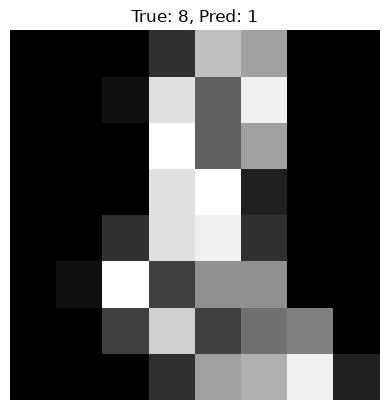

8概率=0.48，1概率=0.49


In [14]:
# 错误样本
wrong_idx = np.where(pred_test != y_test)[0]
print(wrong_idx)
print("错分数量：", len(wrong_idx))

for idx in wrong_idx[:6]:
    plt.figure()
    plt.imshow(X_test[idx].reshape(8, 8), cmap="gray")
    plt.title(f"True: {y_test[idx]}, Pred: {pred_test[idx]}")
    plt.axis("off")
    plt.show()
    print(f"{y_test[idx]}概率={P_test[idx][y_test[idx]]:.2f}，{pred_test[idx]}概率={P_test[idx][pred_test[idx]]:.2f}")